<a href="https://colab.research.google.com/github/TK3107/CNN-MNIST/blob/main/CNN_MNIST_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install gradio

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước bộ dữ liệu:
Kích thước tập train: (60000, 28, 28), (60000,)
Kích thước tập test: (10000, 28, 28), (10000,)


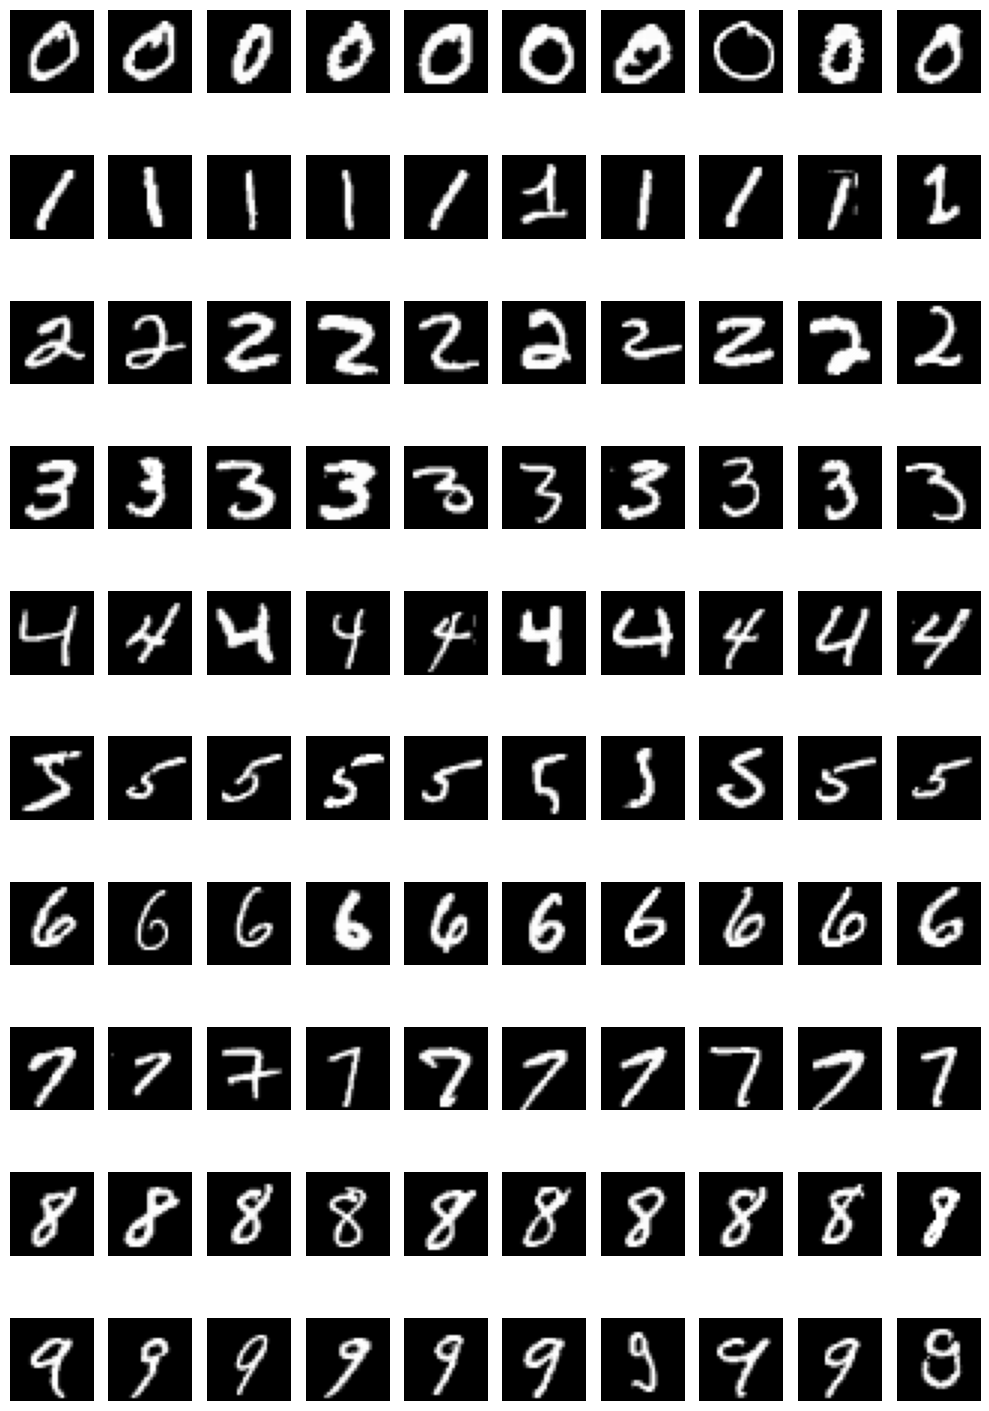

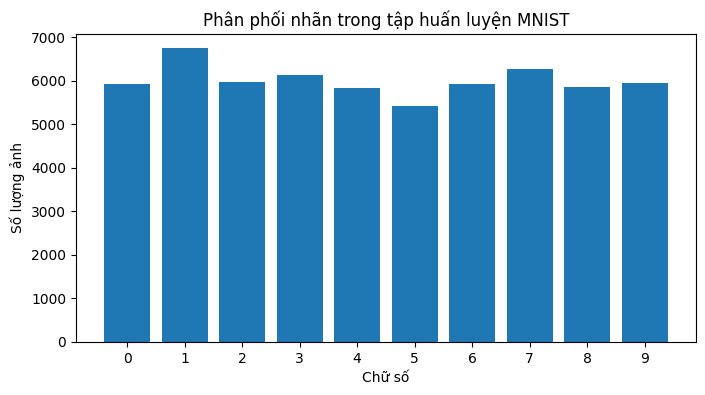

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from tensorflow.keras.datasets import mnist

# Tải dữ liệu
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Kích thước bộ dữ liệu:")
print(f"Kích thước tập train: {X_train.shape}, {y_train.shape}")
print(f"Kích thước tập test: {X_test.shape}, {y_test.shape}")

# Hiển thị vài mẫu
fig, axes = plt.subplots(10, 10, figsize=(10, 15))
for digit in range(10):
    idx = np.where(y_train == digit)[0][:10]
    for i, ax in enumerate(axes[digit]):
        ax.imshow(X_train[idx[i]], cmap='gray')
        ax.axis('off')
plt.tight_layout()
plt.show()

# Vẽ biểu đồ phân bố nhãn
counter = Counter(y_train).most_common()
counter_df = pd.DataFrame(counter, columns=['Số', 'Số lượng']).sort_values(by='Số')
plt.figure(figsize=(8, 4))
plt.bar(counter_df['Số'], counter_df['Số lượng'])
plt.xticks(range(10))
plt.xlabel('Chữ số')
plt.ylabel('Số lượng ảnh')
plt.title('Phân phối nhãn trong tập huấn luyện MNIST')
plt.show()

In [3]:
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# ===== Preprocess cho CNN =====
def preprocess_for_cnn(X_train, X_test, y_train, y_test):
    X_train = X_train.reshape(-1, 28, 28, 1).astype("float32") / 255.0
    X_test = X_test.reshape(-1, 28, 28, 1).astype("float32") / 255.0
    y_train = to_categorical(y_train, 10)
    y_test = to_categorical(y_test, 10)
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = preprocess_for_cnn(X_train, X_test, y_train, y_test)

# ===== Xây dựng mô hình =====
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(128, kernel_size=(3, 3), activation="relu"),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(32, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       204,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 281,770 (1.07 MB)

 Trainable params: 281,770 (1.07 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Huấn luyện
model.fit(X_train, y_train, epochs=15, batch_size=32, validation_split=0.2, verbose=1)

# Hàm đánh giá
def pre_and_eva(model, X_test, y_test):
    y_pred = model.predict(X_test)
    if len(y_pred.shape) > 1: y_pred = np.argmax(y_pred, axis=1)
    if len(y_test.shape) > 1: y_test = np.argmax(y_test, axis=1)

    acc = accuracy_score(y_test, y_pred) * 100
    print(f"\nĐộ chính xác: {acc:.4f}%")
    print("-" * 50)
    print("Ma trận nhầm lẫn:\n", confusion_matrix(y_test, y_pred))
    print("-" * 50)
    print("Classification report:\n", classification_report(y_test, y_pred))

# Gọi hàm đánh giá
pre_and_eva(model, X_test, y_test)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 111s 73ms/step - accuracy: 0.8169 - loss: 0.5568 - val_accuracy: 0.9789 - val_loss: 0.0757
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 113s 75ms/step - accuracy: 0.9249 - loss: 0.2438 - val_accuracy: 0.9828 - val_loss: 0.0609
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 112s 75ms/step - accuracy: 0.9440 - loss: 0.1883 - val_accuracy: 0.9867 - val_loss: 0.0537
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 143s 75ms/step - accuracy: 0.9577 - loss: 0.1484 - val_accuracy: 0.9868 - val_loss: 0.0508
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 140s 74ms/step - accuracy: 0.9644 - loss: 0.1227 - val_accuracy: 0.9888 - val_loss: 0.0456
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 115s 76ms/step - accuracy: 0.9679 - loss: 0.1117 - val_accuracy: 0.9903 - val_loss: 0.0442
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 109s 73ms/step - accuracy: 0.9692 - loss: 0.1059 - val_accuracy: 0.9889 - val_loss: 0.0476
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 142s 73ms/step - accuracy: 

313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step


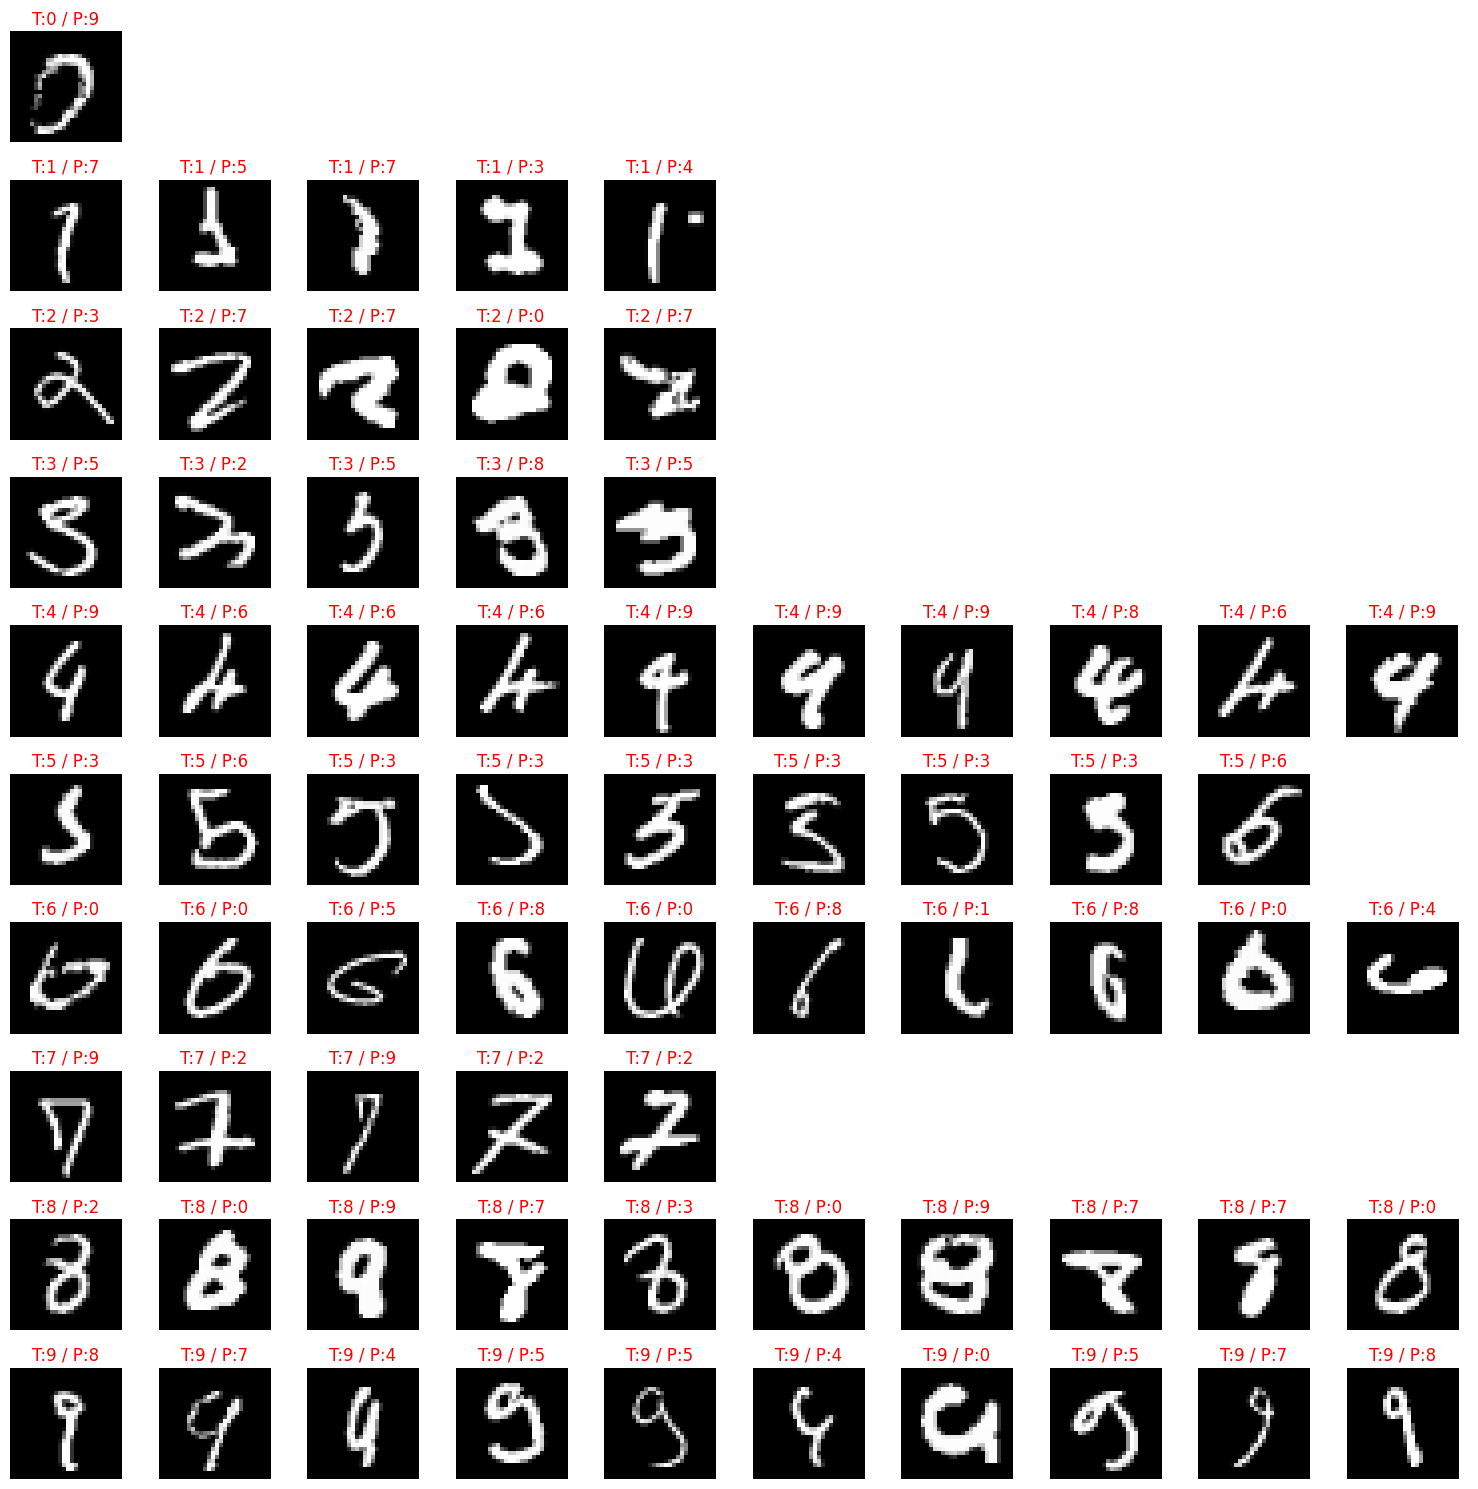

In [5]:
# Lấy dự đoán
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)
y_true = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

# Lọc các mẫu sai
wrong_idx = np.where(y_pred != y_true)[0]

# Vẽ hình
fig, axes = plt.subplots(10, 10, figsize=(15, 15))
for digit in range(10):
    idx = wrong_idx[y_true[wrong_idx] == digit][:10]
    for i in range(10):
        ax = axes[digit, i]
        if i < len(idx):
            img_idx = idx[i]
            ax.imshow(X_test[img_idx].reshape(28, 28), cmap='gray')
            ax.set_title(f"T:{y_true[img_idx]} / P:{y_pred[img_idx]}", color='red')
        ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import gradio as gr
from PIL import Image, ImageOps
import matplotlib.pyplot as plt

# --- Hàm Tiền Xử lý trước UI ---
def input_image(img_array):
    if img_array is None: return None
    if isinstance(img_array, dict): img_array = img_array.get('composite', img_array.get('image'))

    img = Image.fromarray(img_array.astype(np.uint8))

    if img.mode == 'RGBA':
        bg = Image.new('RGB', img.size, (255, 255, 255))
        bg.paste(img, mask=img.split()[3])
        img = bg.convert('L')
    elif img.mode == 'RGB':
        img = img.convert('L')

    if np.mean(np.array(img)) > 128:
        img = ImageOps.invert(img)

    image_preview = img.resize((28, 28), Image.LANCZOS)
    return image_preview

def preprocess_image(img):
    img = np.array(img).astype("float32") / 255.0
    img = img.reshape(1, 28, 28, 1)
    return img

# --- Hàm Dự Đoán ---
def predict_character(img_input, model_choice='CNN'):
    image_preview = input_image(img_input)
    if image_preview is None: return 'Vui lòng vẽ hoặc tải ảnh!', None, ''

    img = preprocess_image(image_preview)
    probs = model.predict(img)[0]

    top5_idx = probs.argsort()[::-1][:5]
    top5_label = [str(i) for i in top5_idx]
    top5_prob = [float(probs[i]) for i in top5_idx]

    best_label, best_conf = top5_label[0], top5_prob[0]

    fig, ax = plt.subplots(figsize=(6, 3))
    bars = ax.barh(top5_label[::-1], top5_prob[::-1])
    ax.set_xlim(0, 1)
    ax.set_xlabel('Confidence')
    ax.set_title('Top-5 Predictions')
    for bar, prob in zip(bars, top5_prob[::-1]):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2, f'{prob:.2%}', va='center')
    plt.tight_layout()

    top5_text = '\n'.join([f'{i+1}. {lbl}: {p:.2%}' for i, (lbl, p) in enumerate(zip(top5_label, top5_prob))])
    result_text = f'✍️ Dự đoán: **{best_label}** ({best_conf:.2%})'

    return result_text, fig, top5_text

# --- Main UI ---
with gr.Blocks() as demo:
    gr.Markdown("# ✍️ Nhận dạng chữ viết tay (CNN - Keras)")
    with gr.Row():
        with gr.Column(scale = 10):
            canvas = gr.Sketchpad(type='numpy')
            result = gr.Markdown()
            image_preview_box = gr.Image(label= "Image Preview")
        with gr.Column(scale = 9):
            plot = gr.Plot()
        with gr.Column(scale = 1):
            with gr.Accordion("Xác suất dự đoán:", open = False):
                text = gr.Textbox(lines = 5)

    btn = gr.Button("Dự đoán")
    show = gr.Button("Show")

    btn.click(fn=predict_character, inputs=canvas, outputs=[result, plot, text])
    show.click(fn=input_image, inputs=canvas, outputs=image_preview_box)

demo.launch(debug = True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://70beac35584a1aa0fd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
